In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pybaseball import statcast_pitcher

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
tjs_url = "https://docs.google.com/spreadsheets/d/1gQujXQQGOVNaiuwSN680Hq-FDVsCwvN-3AazykOBON0/export?format=csv&gid=0"

In [5]:
df_tj_raw = pd.read_csv(tjs_url, header=1)

In [6]:
df_tj_raw.columns = df_tj_raw.columns.str.strip()

In [7]:
player_col = [c for c in df_tj_raw.columns if 'PLAYER' in c.upper()][0]
surg_date_col = [c for c in df_tj_raw.columns if 'SURG' in c.upper() or 'TJ' in c.upper()][0]
return_date_col = [c for c in df_tj_raw.columns if 'RETURN' in c.upper()][0]
level_col = [c for c in df_tj_raw.columns if 'LEVEL' in c.upper()][0]
id_col = [c for c in df_tj_raw.columns if 'MLBAM' in c.upper() or c.lower() == 'mlbamid'][0]

In [8]:
df_tj_raw['Surg_Date_Parsed'] = pd.to_datetime(df_tj_raw[surg_date_col], errors='coerce')
df_tj_raw['Return_Date_Parsed'] = pd.to_datetime(df_tj_raw[return_date_col], errors='coerce')
df_tj_raw['MLBAM_ID_Parsed'] = pd.to_numeric(df_tj_raw[id_col], errors='coerce')

In [9]:
df_tj_filtered = df_tj_raw[
    (df_tj_raw[level_col].astype(str).str.contains('MLB', case=False, na=False)) & 
    (df_tj_raw['Surg_Date_Parsed'].dt.year >= 2016) &
    (df_tj_raw['Return_Date_Parsed'].notna()) &
    (df_tj_raw['MLBAM_ID_Parsed'].notna())
].copy()

In [10]:
df_tj_filtered['MLBAM_ID_Parsed'] = df_tj_filtered['MLBAM_ID_Parsed'].astype(int)
df_tj_filtered['Pre_Year'] = df_tj_filtered['Surg_Date_Parsed'].dt.year - 1
df_tj_filtered['Post_Year'] = df_tj_filtered['Return_Date_Parsed'].dt.year

In [11]:
df_targets = df_tj_filtered.drop_duplicates(subset=['MLBAM_ID_Parsed', 'Pre_Year', 'Post_Year'])

print(f"■ 抽出完了: 条件を満たす対象投手 {len(df_targets)} 名")
display(df_targets[[player_col, surg_date_col, return_date_col, 'Pre_Year', 'Post_Year', 'MLBAM_ID_Parsed']].head())

■ 抽出完了: 条件を満たす対象投手 209 名


,Player,TJ Surgery Date,Return Date (same level),Pre_Year,Post_Year,MLBAM_ID_Parsed
73,Jackson Jobe,6/16/2025,8/8/2026,2024,2026,695549
74,Corbin Burnes,6/11/2025,9/8/2026,2024,2026,669203
75,AJ Smith-Shawver,6/9/2025,7/29/2026,2024,2026,700363
76,Will Brennan,6/9/2025,4/15/2026,2024,2026,686823
77,Ronel Blanco,6/6/2025,7/20/2026,2024,2026,669854


In [12]:
results = []



for idx, row in df_targets.iterrows():
    pitcher_id = row['MLBAM_ID_Parsed']
    name = row[player_col]
    pre_year = int(row['Pre_Year'])
    post_year = int(row['Post_Year'])
    
    try:
        # 1. 術前データの複数年取得 (Statcast開始の2015年以降、手術前年までの直近最大3年間)
        pre_start_year = max(2015, pre_year - 2)
        df_pre_list = []
        
        for y in range(pre_start_year, pre_year + 1):
            df_y = statcast_pitcher(f"{y}-04-01", f"{y}-09-30", pitcher_id)
            if not df_y.empty:
                df_pre_list.append(df_y)
                
        # 複数年データを結合し、フォーシーム (FF) のみを抽出
        df_pre_all = pd.concat(df_pre_list, ignore_index=True) if df_pre_list else pd.DataFrame()
        ff_pre = df_pre_all[df_pre_all['pitch_type'] == 'FF'] if not df_pre_all.empty else pd.DataFrame()
        
        # 2. 復帰シーズン (4月〜9月) のデータ取得
        df_post = statcast_pitcher(f"{post_year}-04-01", f"{post_year}-09-30", pitcher_id)
        ff_post = df_post[df_post['pitch_type'] == 'FF'] if not df_post.empty else pd.DataFrame()
        
        # 両期間でフォーシームを10球以上投げている選手のみ集計対象に設定
        if len(ff_pre) >= 10 and len(ff_post) >= 10:
            results.append({
                'MLBAM_ID': pitcher_id,
                'Name': name,
                'Pre_Period': f"{pre_start_year}-{pre_year}" if pre_start_year != pre_year else f"{pre_year}",
                'Post_Year': post_year,
                'Pre_Speed': ff_pre['release_speed'].mean(),
                'Post_Speed': ff_post['release_speed'].mean(),
                'Pre_Spin': ff_pre['release_spin_rate'].mean(),
                'Post_Spin': ff_post['release_spin_rate'].mean(),
                'Pre_Count': len(ff_pre),
                'Post_Count': len(ff_post)
            })
            print(f"✓ 成功: {name} (術前期間:{pre_start_year}-{pre_year} [球数:{len(ff_pre)}] / 復帰:{post_year} [球数:{len(ff_post)}])")
        else:
            print(f"- スキップ (球数不足): {name} (術前FF:{len(ff_pre)}, 復帰FF:{len(ff_post)})")
            
    except Exception as e:
        print(f"× エラー: {name} の取得失敗 ({e})")

Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 成功: Jackson Jobe (術前期間:2022-2024 [球数:27] / 復帰:2026 [球数:241])
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
- スキップ (球数不足): Corbin Burnes (術前FF:9, 復帰FF:0)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 成功: AJ Smith-Shawver (術前期間:2022-2024 [球数:292] / 復帰:2026 [球数:224])
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
- スキップ (球数不足): Will Brennan (術前FF:0, 復帰FF:0)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 成功: Ronel Blanco (術前期間:2022-2024 [球数:1474] / 復帰:2026 [球数:211])
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 成功: Evan Phillips (術前期間:2022-2024 [球数:680] / 復帰:2026 [球数:193])
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 成功: Hayden Wesneski (術前期間:2022

In [13]:
df_analysis = pd.DataFrame(results)
print(f"集計完了: 有効分析サンプル数 {len(df_analysis)} 名")
display(df_analysis.head(10))

集計完了: 有効分析サンプル数 149 名


,MLBAM_ID,Name,Pre_Period,Post_Year,Pre_Speed,Post_Speed,Pre_Spin,Post_Spin,Pre_Count,Post_Count
0,695549,Jackson Jobe,2022-2024,2026,97.048148,97.572199,2357.777778,2427.439834,27,241
1,700363,AJ Smith-Shawver,2022-2024,2026,94.732877,96.298661,2189.636986,2163.879464,292,224
2,669854,Ronel Blanco,2022-2024,2026,93.770285,93.383412,2239.892130,2302.478673,1474,211
3,623465,Evan Phillips,2022-2024,2026,96.202353,96.869948,2370.362297,2437.192708,680,193
4,669713,Hayden Wesneski,2022-2024,2026,94.305005,93.530275,2135.208333,2207.766055,919,218
5,686796,Blake Walston,2022-2024,2026,91.442982,91.635294,2089.850877,2094.058824,114,17
6,543037,Gerrit Cole,2022-2024,2026,96.989941,96.795450,2410.599852,2322.182011,4056,945
7,676105,Jeff Criswell,2022-2024,2026,95.399342,95.354545,2328.677632,2367.151515,152,33
8,605397,Joe Musgrove,2021-2023,2026,93.097352,95.620000,2579.588779,2731.800000,1624,10
9,682227,Brandon Williamson,2021-2023,2026,92.793185,92.849242,2149.426184,2194.734848,719,132


In [14]:
df_analysis['Speed_Diff'] = df_analysis['Post_Speed'] - df_analysis['Pre_Speed']
df_analysis['Spin_Diff'] = df_analysis['Post_Spin'] - df_analysis['Pre_Spin']

In [15]:
corr_speed = df_analysis['Pre_Speed'].corr(df_analysis['Post_Speed'])
corr_spin = df_analysis['Pre_Spin'].corr(df_analysis['Post_Spin'])

In [16]:
print("トミー・ジョン手術 前後における球速・回転数 全体分析結果 ")
print(f"■ 有効サンプル数 (N): {len(df_analysis)} 名")
print(f"■ 平均球速 (術前 → 復帰後): {df_analysis['Pre_Speed'].mean():.2f} mph → {df_analysis['Post_Speed'].mean():.2f} mph")
print(f"■ 平均球速変化量: {df_analysis['Speed_Diff'].mean():.2f} mph")
print(f"■ 球速の相関係数 (r): {corr_speed:.3f}")
print("-" * 50)
print(f"■ 平均回転数 (術前 → 復帰後): {df_analysis['Pre_Spin'].mean():.1f} rpm → {df_analysis['Post_Spin'].mean():.1f} rpm")
print(f"■ 平均回転数変化量: {df_analysis['Spin_Diff'].mean():.1f} rpm")
print(f"■ 回転数の相関係数 (r): {corr_spin:.3f}")

トミー・ジョン手術 前後における球速・回転数 全体分析結果 
■ 有効サンプル数 (N): 149 名
■ 平均球速 (術前 → 復帰後): 94.51 mph → 94.12 mph
■ 平均球速変化量: -0.40 mph
■ 球速の相関係数 (r): 0.757
--------------------------------------------------
■ 平均回転数 (術前 → 復帰後): 2294.9 rpm → 2296.1 rpm
■ 平均回転数変化量: 1.2 rpm
■ 回転数の相関係数 (r): 0.766


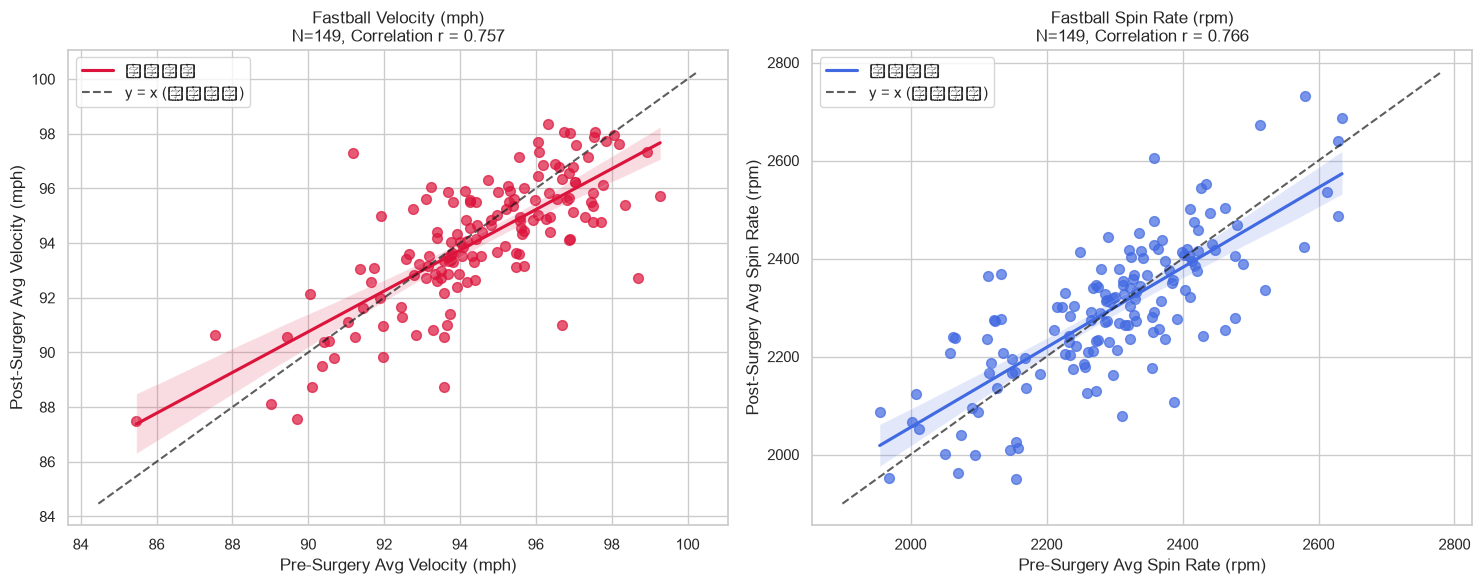

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.regplot(
    data=df_analysis, x='Pre_Speed', y='Post_Speed', ax=axes[0],
    color='crimson', scatter_kws={'alpha':0.7, 's':50}, line_kws={'label': '回帰直線'}
)
min_sp = min(df_analysis['Pre_Speed'].min(), df_analysis['Post_Speed'].min()) - 1
max_sp = max(df_analysis['Pre_Speed'].max(), df_analysis['Post_Speed'].max()) + 1
axes[0].plot([min_sp, max_sp], [min_sp, max_sp], 'k--', alpha=0.7, label='y = x (完全維持)')

axes[0].set_title(f'Fastball Velocity (mph)\nN={len(df_analysis)}, Correlation r = {corr_speed:.3f}')
axes[0].set_xlabel('Pre-Surgery Avg Velocity (mph)')
axes[0].set_ylabel('Post-Surgery Avg Velocity (mph)')
axes[0].legend()

sns.regplot(
    data=df_analysis, x='Pre_Spin', y='Post_Spin', ax=axes[1],
    color='royalblue', scatter_kws={'alpha':0.7, 's':50}, line_kws={'label': '回帰直線'}
)
min_spn = min(df_analysis['Pre_Spin'].min(), df_analysis['Post_Spin'].min()) - 50
max_spn = max(df_analysis['Pre_Spin'].max(), df_analysis['Post_Spin'].max()) + 50
axes[1].plot([min_spn, max_spn], [min_spn, max_spn], 'k--', alpha=0.7, label='y = x (完全維持)')

axes[1].set_title(f'Fastball Spin Rate (rpm)\nN={len(df_analysis)}, Correlation r = {corr_spin:.3f}')
axes[1].set_xlabel('Pre-Surgery Avg Spin Rate (rpm)')
axes[1].set_ylabel('Post-Surgery Avg Spin Rate (rpm)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [18]:
OUT_EVENTS = [
    'field_out', 'strikeout', 'strikeout_double_play', 'force_out', 
    'grounded_into_double_play', 'double_play', 'triple_play', 
    'fielders_choice', 'fielders_choice_out', 'sac_fly', 'sac_bunt', 
    'sac_fly_double_play', 'sac_bunt_double_play'
]

In [19]:
stats_results = []

for idx, row in df_targets.iterrows():
    pitcher_id = row['MLBAM_ID_Parsed']
    name = row[player_col]
    pre_year = int(row['Pre_Year'])
    post_year = int(row['Post_Year'])
    
    try:
        pre_start_year = max(2015, pre_year - 2)
        df_pre_list = []
        
        for y in range(pre_start_year, pre_year + 1):
            df_y = statcast_pitcher(f"{y}-04-01", f"{y}-09-30", pitcher_id)
            if not df_y.empty:
                df_pre_list.append(df_y)

        df_pre_all = pd.concat(df_pre_list, ignore_index=True) if df_pre_list else pd.DataFrame()

        df_post_all = statcast_pitcher(f"{post_year}-04-01", f"{post_year}-09-30", pitcher_id)

        pre_events = df_pre_all[df_pre_all['events'].notna()] if not df_pre_all.empty else pd.DataFrame()
        post_events = df_post_all[df_post_all['events'].notna()] if not df_post_all.empty else pd.DataFrame()
        
        # 術前合計で50打席以上、復帰年で50打席以上のデータがある選手に限定
        if len(pre_events) >= 50 and len(post_events) >= 50:
            
            def calc_metrics(events_df):
                pa = len(events_df)
                k = events_df['events'].isin(['strikeout', 'strikeout_double_play']).sum()
                bb = events_df['events'].isin(['walk', 'intent_walk']).sum()
                hbp = (events_df['events'] == 'hit_by_pitch').sum()
                hr = (events_df['events'] == 'home_run').sum()
                outs = events_df['events'].isin(OUT_EVENTS).sum()
                ip = outs / 3.0
                
                k_rate = (k / pa) * 100
                bb_rate = (bb / pa) * 100
                k_bb_rate = k_rate - bb_rate
                
                # FIP (定数 C は概算値 3.20 を適用)
                fip = ((13 * hr + 3 * (bb + hbp) - 2 * k) / ip) + 3.20 if ip > 0 else np.nan
                
                return {'PA': pa, 'IP': ip, 'K%': k_rate, 'BB%': bb_rate, 'K-BB%': k_bb_rate, 'FIP': fip}

            pre_m = calc_metrics(pre_events)
            post_m = calc_metrics(post_events)
            
            stats_results.append({
                'MLBAM_ID': pitcher_id,
                'Name': name,
                'Pre_Period': f"{pre_start_year}-{pre_year}" if pre_start_year != pre_year else f"{pre_year}",
                'Post_Year': post_year,
                'Pre_PA': pre_m['PA'],
                'Post_PA': post_m['PA'],
                'Pre_K%': pre_m['K%'],
                'Post_K%': post_m['K%'],
                'Pre_BB%': pre_m['BB%'],
                'Post_BB%': post_m['BB%'],
                'Pre_K-BB%': pre_m['K-BB%'],
                'Post_K-BB%': post_m['K-BB%'],
                'Pre_FIP': pre_m['FIP'],
                'Post_FIP': post_m['FIP']
            })
            print(f"✓ 集計完了: {name} (術前期間:{pre_start_year}-{pre_year} [PA:{pre_m['PA']}] / 復帰PA:{post_m['PA']})")
        else:
            print(f"- スキップ (打席数不足): {name} (術前PA:{len(pre_events)}, 術後PA:{len(post_events)})")
            
    except Exception as e:
        print(f"× エラー: {name} ({e})")

Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
- スキップ (打席数不足): Jackson Jobe (術前PA:16, 術後PA:194)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
- スキップ (打席数不足): Corbin Burnes (術前PA:2339, 術後PA:47)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 集計完了: AJ Smith-Shawver (術前期間:2022-2024 [PA:123] / 復帰PA:145)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
- スキップ (打席数不足): Will Brennan (術前PA:0, 術後PA:0)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 集計完了: Ronel Blanco (術前期間:2022-2024 [PA:936] / 復帰PA:143)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 集計完了: Evan Phillips (術前期間:2022-2024 [PA:682] / 復帰PA:106)
Gathering Player Data
Gathering Player Data
Gathering Player Data
Gathering Player Data
✓ 集計完了: Hayden Wesneski (術前期間:2022-2024 [PA:771] / 復帰PA:246

In [20]:
df_stats_analysis = pd.DataFrame(stats_results)
print(f"集計完了: 成績指標の有効サンプル数 {len(df_stats_analysis)} 名")
display(df_stats_analysis.head(10))

集計完了: 成績指標の有効サンプル数 108 名


,MLBAM_ID,Name,Pre_Period,Post_Year,Pre_PA,Post_PA,Pre_K%,Post_K%,Pre_BB%,Post_BB%,Pre_K-BB%,Post_K-BB%,Pre_FIP,Post_FIP
0,700363,AJ Smith-Shawver,2022-2024,2026,123,145,19.512195,18.620690,10.569106,11.034483,8.943089,7.586207,6.097727,6.167391
1,669854,Ronel Blanco,2022-2024,2026,936,143,24.038462,20.279720,10.683761,11.188811,13.354701,9.090909,4.670138,6.673684
2,623465,Evan Phillips,2022-2024,2026,682,106,29.032258,31.132075,6.744868,5.660377,22.287390,25.471698,2.871315,3.979221
3,669713,Hayden Wesneski,2022-2024,2026,771,246,22.957198,18.699187,7.652399,8.130081,15.304799,10.569106,4.841405,3.650867
4,664849,Danny Young,2022-2024,2026,232,65,28.017241,23.076923,9.482759,20.000000,18.534483,3.076923,3.555263,8.229412
5,543037,Gerrit Cole,2022-2024,2026,1978,520,28.463094,25.192308,6.420627,4.807692,22.042467,20.384615,3.447745,4.040000
6,682227,Brandon Williamson,2021-2023,2026,504,209,20.039683,15.789474,7.936508,13.397129,12.103175,2.392344,4.590029,5.617910
7,665622,Luis Medina,2021-2023,2026,495,315,21.414141,29.206349,11.515152,12.063492,9.898990,17.142857,4.756604,3.673684
8,680694,Kyle Bradish,2021-2023,2025,1151,126,23.370982,37.301587,7.298002,7.936508,16.072980,29.365079,3.811321,2.482609
9,664299,Cristian Javier,2021-2023,2025,1620,158,28.641975,21.518987,9.938272,9.493671,18.703704,12.025316,4.154783,3.732710


In [22]:
df_stats_analysis['K%_Diff'] = df_stats_analysis['Post_K%'] - df_stats_analysis['Pre_K%']
df_stats_analysis['FIP_Diff'] = df_stats_analysis['Post_FIP'] - df_stats_analysis['Pre_FIP']
df_stats_analysis['K-BB%_Diff'] = df_stats_analysis['Post_K-BB%'] - df_stats_analysis['Pre_K-BB%']

# ピアソン相関係数
corr_k = df_stats_analysis['Pre_K%'].corr(df_stats_analysis['Post_K%'])
corr_fip = df_stats_analysis['Pre_FIP'].corr(df_stats_analysis['Post_FIP'])
corr_k_bb = df_stats_analysis['Pre_K-BB%'].corr(df_stats_analysis['Post_K-BB%'])

print(f"■ 対象サンプル数 (N): {len(df_stats_analysis)} 名")
print("-" * 50)
print(f"■ K% (奪三振率):   {df_stats_analysis['Pre_K%'].mean():.2f}% → {df_stats_analysis['Post_K%'].mean():.2f}% (平均変化: {df_stats_analysis['K%_Diff'].mean():+.2f}%, 相関 r: {corr_k:.3f})")
print(f"■ BB% (与四球率): {df_stats_analysis['Pre_BB%'].mean():.2f}% → {df_stats_analysis['Post_BB%'].mean():.2f}%")
print(f"■ K-BB%:         {df_stats_analysis['Pre_K-BB%'].mean():.2f}% → {df_stats_analysis['Post_K-BB%'].mean():.2f}% (平均変化: {df_stats_analysis['K-BB%_Diff'].mean():+.2f}%, 相関 r: {corr_k_bb:.3f})")
print(f"■ FIP (守備独立防御率): {df_stats_analysis['Pre_FIP'].mean():.2f} → {df_stats_analysis['Post_FIP'].mean():.2f} (平均変化: {df_stats_analysis['FIP_Diff'].mean():+.2f}, 相関 r: {corr_fip:.3f})")

■ 対象サンプル数 (N): 108 名
--------------------------------------------------
■ K% (奪三振率):   24.10% → 22.64% (平均変化: -1.46%, 相関 r: 0.385)
■ BB% (与四球率): 8.68% → 9.20%
■ K-BB%:         15.42% → 13.44% (平均変化: -1.98%, 相関 r: 0.240)
■ FIP (守備独立防御率): 4.11 → 4.58 (平均変化: +0.46, 相関 r: -0.086)


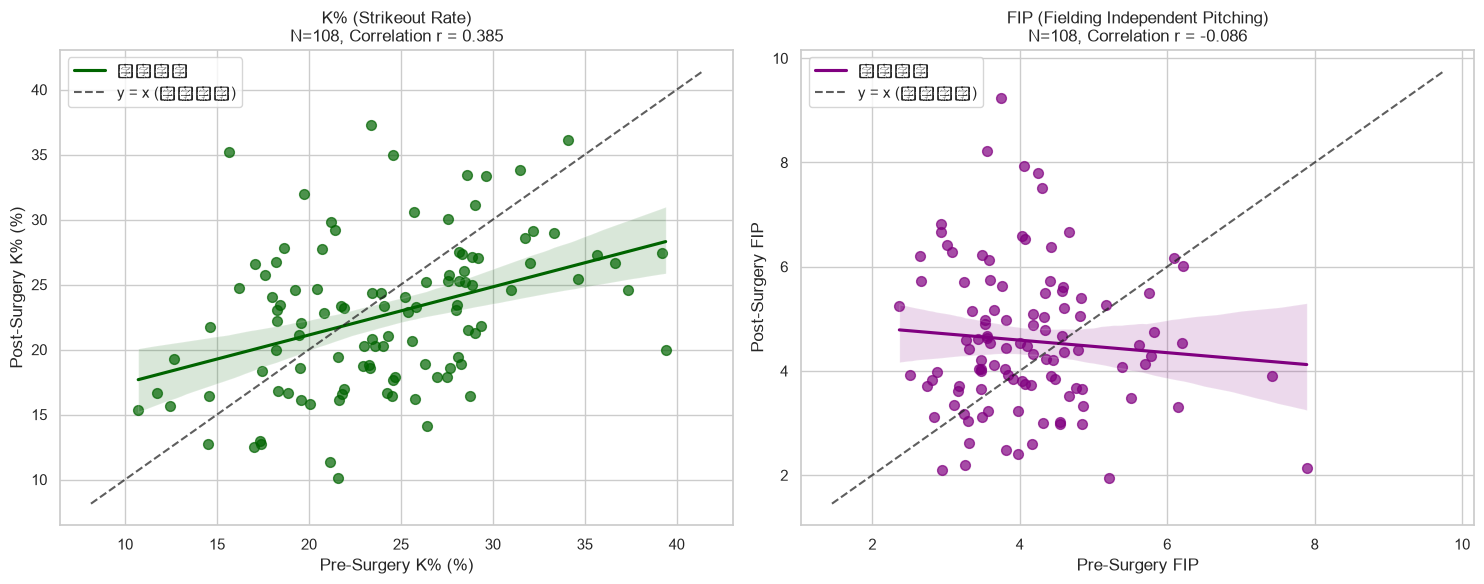

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. K% (奪三振率) の散布図 (左図: 高いほど優秀)
sns.regplot(
    data=df_stats_analysis, x='Pre_K%', y='Post_K%', ax=axes[0],
    color='darkgreen', scatter_kws={'alpha':0.7, 's':50}, line_kws={'label': '回帰直線'}
)

min_k = min(df_stats_analysis['Pre_K%'].min(), df_stats_analysis['Post_K%'].min()) - 2
max_k = max(df_stats_analysis['Pre_K%'].max(), df_stats_analysis['Post_K%'].max()) + 2
axes[0].plot([min_k, max_k], [min_k, max_k], 'k--', alpha=0.7, label='y = x (完全維持)')

axes[0].set_title(f'K% (Strikeout Rate)\nN={len(df_stats_analysis)}, Correlation r = {corr_k:.3f}')
axes[0].set_xlabel('Pre-Surgery K% (%)')
axes[0].set_ylabel('Post-Surgery K% (%)')
axes[0].legend()

#2. FIP (守備独立防御率) の散布図 (右図: 低いほど優秀) 

sns.regplot(
    data=df_stats_analysis, x='Pre_FIP', y='Post_FIP', ax=axes[1],
    color='purple', scatter_kws={'alpha':0.7, 's':50}, line_kws={'label': '回帰直線'}
)

min_fip = min(df_stats_analysis['Pre_FIP'].min(), df_stats_analysis['Post_FIP'].min()) - 0.5
max_fip = max(df_stats_analysis['Pre_FIP'].max(), df_stats_analysis['Post_FIP'].max()) + 0.5
axes[1].plot([min_fip, max_fip], [min_fip, max_fip], 'k--', alpha=0.7, label='y = x (完全維持)')

axes[1].set_title(f'FIP (Fielding Independent Pitching)\nN={len(df_stats_analysis)}, Correlation r = {corr_fip:.3f}')
axes[1].set_xlabel('Pre-Surgery FIP')
axes[1].set_ylabel('Post-Surgery FIP')
axes[1].legend()

plt.tight_layout()
plt.show()

In [24]:
df_tj_mlb = df_tj_raw[
    (df_tj_raw[level_col].astype(str).str.contains('MLB', case=False, na=False)) & 
    (df_tj_raw['Surg_Date_Parsed'].notna())
].copy()

# 手術年と手術月を取得
df_tj_mlb['Surg_Year'] = df_tj_mlb['Surg_Date_Parsed'].dt.year
df_tj_mlb['Surg_Month'] = df_tj_mlb['Surg_Date_Parsed'].dt.month

# Statcast導入以降（2015年〜直近年度）のデータに絞り込み
df_recent_tj = df_tj_mlb[(df_tj_mlb['Surg_Year'] >= 2015) & (df_tj_mlb['Surg_Year'] <= 2025)].copy()

# 年別件数の集計
yearly_counts = df_recent_tj['Surg_Year'].value_counts().sort_index().reset_index()
yearly_counts.columns = ['Year', 'TJ_Count']

# ピッチクロック区分（2023年以降＝導入後）
yearly_counts['Era'] = np.where(yearly_counts['Year'] >= 2023, 'With Pitch Clock (2023+)', 'Pre Pitch Clock (2015-2022)')

# 区分ごとの平均年間発生数の計算
era_avg = yearly_counts.groupby('Era')['TJ_Count'].mean().round(1).to_dict()

print("=== MLBにおける年間TJ手術発生件数（2015年〜） ===")
display(yearly_counts)

print("\n=== ピッチクロック導入前後での年間平均TJ手術件数 ===")
for era, avg in era_avg.items():
    print(f"■ {era}: 年間平均 {avg} 件")

=== MLBにおける年間TJ手術発生件数（2015年〜） ===


,Year,TJ_Count,Era
0,2015,26,Pre Pitch Clock (2015-2022)
1,2016,19,Pre Pitch Clock (2015-2022)
2,2017,20,Pre Pitch Clock (2015-2022)
3,2018,28,Pre Pitch Clock (2015-2022)
4,2019,19,Pre Pitch Clock (2015-2022)
5,2020,29,Pre Pitch Clock (2015-2022)
6,2021,35,Pre Pitch Clock (2015-2022)
7,2022,28,Pre Pitch Clock (2015-2022)
8,2023,34,With Pitch Clock (2023+)
9,2024,34,With Pitch Clock (2023+)



=== ピッチクロック導入前後での年間平均TJ手術件数 ===
■ Pre Pitch Clock (2015-2022): 年間平均 25.5 件
■ With Pitch Clock (2023+): 年間平均 32.3 件


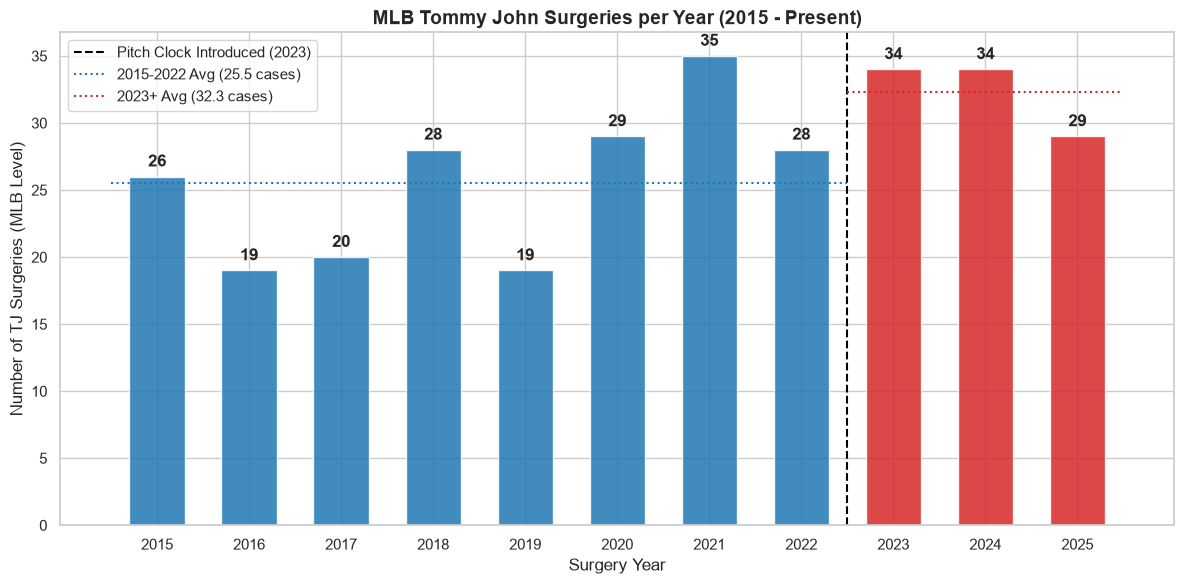

In [25]:
plt.figure(figsize=(12, 6))

# ピッチクロック導入前後で色分けした棒グラフ
colors = ['#1f77b4' if y < 2023 else '#d62728' for y in yearly_counts['Year']]
bars = plt.bar(yearly_counts['Year'], yearly_counts['TJ_Count'], color=colors, width=0.6, alpha=0.85)

# 棒グラフの上に件数を表示
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, int(yval), ha='center', va='bottom', fontweight='bold')

# ピッチクロック導入境界線 (2023年シーズンの始まり)
plt.axvline(x=2022.5, color='black', linestyle='--', linewidth=1.5, label='Pitch Clock Introduced (2023)')

# 導入前後の平均値を示す水平線
pre_avg = era_avg.get('Pre Pitch Clock (2015-2022)', 0)
post_avg = era_avg.get('With Pitch Clock (2023+)', 0)
plt.hlines(y=pre_avg, xmin=2014.5, xmax=2022.5, color='#1f77b4', linestyle=':', label=f'2015-2022 Avg ({pre_avg} cases)')
plt.hlines(y=post_avg, xmin=2022.5, xmax=2025.5, color='#d62728', linestyle=':', label=f'2023+ Avg ({post_avg} cases)')

plt.title('MLB Tommy John Surgeries per Year (2015 - Present)', fontsize=14, fontweight='bold')
plt.xlabel('Surgery Year', fontsize=12)
plt.ylabel('Number of TJ Surgeries (MLB Level)', fontsize=12)
plt.xticks(yearly_counts['Year'])
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()